### Chargement du jeu de données Iris de scikit-learn

In [58]:
import sys; print(sys.executable)

C:\Users\togno\iris-project\ml\.venv\Scripts\python.exe


In [59]:

from sklearn.datasets import load_iris

In [60]:
iris = load_iris()

In [61]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

### Conversion en DataFrame pandas pour plus de lisiblité 

In [62]:
import pandas as pd

X = iris.data
y = iris.target


df = pd.DataFrame(
    X,
    columns=iris.feature_names
)

df["species"] = iris.target_names[y]

print(df.head())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


### Exploration des données

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [64]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [65]:
df["species"].describe()

count        150
unique         3
top       setosa
freq          50
Name: species, dtype: object

In [66]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

##### on peut voir ici que les classes sont équilibrées 

In [67]:
df.isna().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [68]:
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

##### On peut voir qu'il n'y a pas de valeurs manquantes ni de valeurs nulles dans les données ce qui nous dispense de l'imputation des données mais il sera fait dans les pipelines à titre d'apprentissage 

### Séparation des variables 

In [69]:
X = df.drop("species", axis=1)
y = df["species"]

In [70]:
print(X.shape, y.shape)

(150, 4) (150,)


In [71]:
print("Prenières valeurs de X : ")
print(X.head())
print("Prenières valeurs de y : ")
print(y.head())

Prenières valeurs de X : 
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
Prenières valeurs de y : 
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


##### Découpage des données en train/test

In [72]:
from sklearn.model_selection import train_test_split

In [73]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, random_state=42, stratify=y, test_size=0.2
)

### Prétraitement des données (imputation et standardisation)

In [74]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression # Modèle de base pour la classification
from sklearn.metrics import accuracy_score

#  Construire le pipeline
steps = [
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
]
pipeline = Pipeline(steps=steps)

#  Entraîner le pipeline sur le train
pipeline.fit(X_train, y_train)

#  Prédire sur le test
y_pred = pipeline.predict(X_test)

#  Évaluer le modèle
print("Accuracy :", accuracy_score(y_test, y_pred))

Accuracy : 0.9333333333333333


### Comparaison avec un modèle de référence (DummyClassifier)

In [75]:
from sklearn.dummy import DummyClassifier

# Créer le modèle de référence
baseline = DummyClassifier(strategy="most_frequent") # prédict toujours la classe la plus fréquente 


#  Entraîner les deux modèles
baseline.fit(X_train, y_train)
pipeline.fit(X_train, y_train)

#  Prédire sur le jeu de test
y_pred_baseline = baseline.predict(X_test)
y_pred = pipeline.predict(X_test)

#  Comparer les performances
print("Accuracy baseline :",
      accuracy_score(y_test, y_pred_baseline))

print("Accuracy Logistic Regression :",
      accuracy_score(y_test, y_pred))

Accuracy baseline : 0.3333333333333333
Accuracy Logistic Regression : 0.9333333333333333


On voit ici que notre modèle de régression logistique fait nettement mieux que le modèle de référence

### Affichage de la matrice de confusion et du rapport de classification (métriques)

In [76]:
from sklearn.metrics import confusion_matrix, classification_report

# 1 Matrice de confusion 

cm = confusion_matrix(y_true=y_test, y_pred=y_pred)

print("Confusion matrix ")
print(cm)

# 2 Rapport de classification 
print("\nRapport de classification :")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Confusion matrix 
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Rapport de classification :
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



##### Ici on observe que le modèle classe correctement la setosa et fais une erreur pour chacune des deux autres 

### Visualisation de la matrice de Confusion

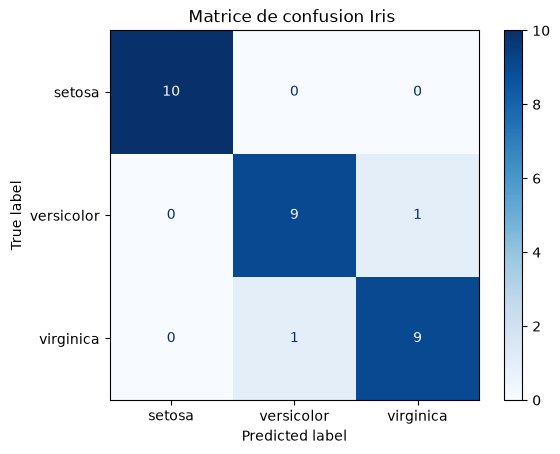

In [77]:
import matplotlib.pyplot as plt 
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names,
    cmap="Blues"
    )
plt.title("Matrice de confusion Iris ")

plt.show()

### Passage à la validation croisée 

In [78]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True, 
    random_state=42
)

# StratifiedKFold au lieu de KFold pour une assurer d'une répartition égale des classes de la cible dans les plis 

scores = cross_val_score(
    pipeline,
    X_train,
    y_train,
    cv=cv, 
    scoring="accuracy"
)

# On calcule les scores avec l'accuracy car les classes sont équilibrées et qu'on peut se permettre de d'utiliser
print("Score par pli : ", scores)
print("Accuracy moyenne :", scores.mean())
print("Ecart-type:", scores.std())


Score par pli :  [0.95833333 1.         0.95833333 0.95833333 0.91666667]
Accuracy moyenne : 0.9583333333333334
Ecart-type: 0.026352313834736508


#### Les scores, la moyenne et l'écart-type nous révèlent que le modèle est plus ou moins stable avec une faible dispersion de l'exactitude entre les plis 

## Comparaison de plusieurs modèles 

In [79]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier


In [80]:
# Construction du dictionnaire des modèles et les prétraitements associés 
models = {
    "Logistic Regression": Pipeline(
        [
            ("imputer",SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=1000))
        ]
    ),
    "KNN": Pipeline(
        [
            ("imputer",SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ]
    ),
    "SVM": Pipeline(
        [
            ("imputer",SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVC())
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("imputer",SimpleImputer(strategy="median")),
            ("model", RandomForestClassifier(n_estimators=100, random_state=42))
        ]
    )
}

# Le random Forest est insensible à l'échelle des données raison pour laquelle on peut se passer de la mise à l'échelle

# Stratification avec 5 folds et reproductible

cv = StratifiedKFold(
    n_splits=5,
    random_state=42,
    shuffle=True
)

### Entrainement sur chaque modèle avec ses hyperparamètres par défauts sur les même plis 

In [81]:
results = []
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")

# Construction d'un jeu de données du résultats pour analyse
    results.append({
        "Modèle":name,
        "Accuracy moyenne": scores.mean(),
        "Ecart-type": scores.std().round(3),
        "Scores par pli ": scores.round(3).tolist()
    })


In [82]:
print(results)

[{'Modèle': 'Logistic Regression', 'Accuracy moyenne': np.float64(0.9583333333333334), 'Ecart-type': np.float64(0.026), 'Scores par pli ': [0.958, 1.0, 0.958, 0.958, 0.917]}, {'Modèle': 'KNN', 'Accuracy moyenne': np.float64(0.9583333333333334), 'Ecart-type': np.float64(0.026), 'Scores par pli ': [0.958, 1.0, 0.958, 0.917, 0.958]}, {'Modèle': 'SVM', 'Accuracy moyenne': np.float64(0.9666666666666668), 'Ecart-type': np.float64(0.017), 'Scores par pli ': [0.958, 1.0, 0.958, 0.958, 0.958]}, {'Modèle': 'Random Forest', 'Accuracy moyenne': np.float64(0.95), 'Ecart-type': np.float64(0.031), 'Scores par pli ': [0.958, 1.0, 0.958, 0.917, 0.917]}]


In [83]:
# Conversion en dataframe pandas
results_df = pd.DataFrame(
    results
)
results_df = results_df.sort_values(
    by="Accuracy moyenne",
    ascending=False
)
print(results_df.to_string(index=False))

             Modèle  Accuracy moyenne  Ecart-type                   Scores par pli 
                SVM          0.966667       0.017 [0.958, 1.0, 0.958, 0.958, 0.958]
Logistic Regression          0.958333       0.026 [0.958, 1.0, 0.958, 0.958, 0.917]
                KNN          0.958333       0.026 [0.958, 1.0, 0.958, 0.917, 0.958]
      Random Forest          0.950000       0.031 [0.958, 1.0, 0.958, 0.917, 0.917]


In [84]:
results_df

,Modèle,Accuracy moyenne,Ecart-type,Scores par pli
2,SVM,0.966667,0.017,"[0.958, 1.0, 0.958, 0.958, 0.958]"
0,Logistic Regression,0.958333,0.026,"[0.958, 1.0, 0.958, 0.958, 0.917]"
1,KNN,0.958333,0.026,"[0.958, 1.0, 0.958, 0.917, 0.958]"
3,Random Forest,0.950000,0.031,"[0.958, 1.0, 0.958, 0.917, 0.917]"


##### On peut constater que le modèle le mieux performant pour ces donnés est le support vecteur machine SVM (moyenne élevée et l'écart-type faible)

### Sélection de SVM et réglage de ses hyperparamètres 

In [85]:
from sklearn.model_selection import GridSearchCV

In [86]:
# Construction du pipeline 
svm_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model",SVC(probability=True))
])

# Définition de l'espace des hyperparamètres
params_grid = {
    "model__C": [0.1, 1.0, 10, 100],
    "model__kernel": ["linear", "rbf"],
    "model__gamma": ["scale", 0.01, 0.1, 1]
}

# Validation croisée à 5 blocs 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Recherche de grille sur le pipeline et l'espace d'hyperparamètres
grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=params_grid,
    refit=True,
    scoring="accuracy",
    n_jobs=-1,
    cv=cv
)

# Entrainement du pipeline par la recherche de grille 
grid_search.fit(X_train, y_train)

# Affichage des meilleurs paramètres et scores 
print("Meilleurs paramètres :", grid_search.best_params_)
print("Meilleurs accuracy moyenne :", grid_search.best_score_)

Meilleurs paramètres : {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Meilleurs accuracy moyenne : 0.975


C:\Users\togno\iris-project\ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


##### La meilleur valeur de C étant nettement en dessous de la valeur par défaut avec le meilleur noyau qui est linéaire montre que le jeu de données est linéairement séparable 

### Sélection du modèle avec ses meilleurs hyperparamètres et évaluation sur le jeu de test 

In [87]:
from sklearn.metrics import (
    accuracy_score,
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt

# Sélection du modèle avec ses meilleurs hyperparamètres 

best_svc = grid_search.best_estimator_

# Réentrainement du model 

best_svc.fit(X_train, y_train)

# Evaluation sur le jeu de test
svc_y_pred = best_svc.predict(X_test)

C:\Users\togno\iris-project\ml\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [88]:
print("\nAccuracy Score : ", accuracy_score(y_test, svc_y_pred)) # Exactitude

print("\nMatrice de confusion: ") # Matrice de confusion
print(confusion_matrix(y_test, svc_y_pred))




Accuracy Score :  0.9333333333333333

Matrice de confusion: 
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [89]:
print("Rapport de classification")  # rapport de classification
print(classification_report(y_test, svc_y_pred, target_names=iris.target_names))

Rapport de classification
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



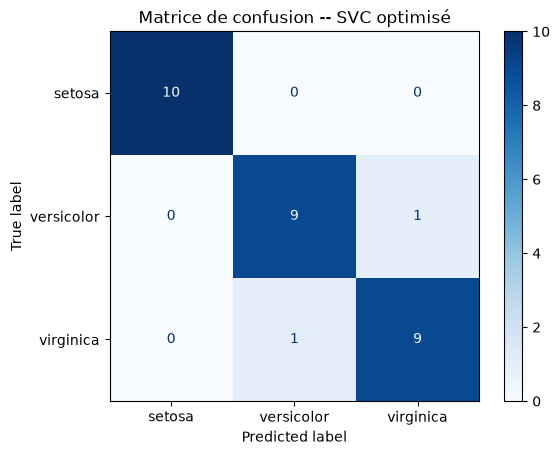

In [90]:
ConfusionMatrixDisplay.from_predictions(
    y_test, # y_true
    svc_y_pred, # y_pred
    display_labels=iris.target_names,
    cmap="Blues"
)
plt.title("Matrice de confusion -- SVC optimisé")
plt.show()

### On voit que le modèle SVM optimisé ne fais pas mieux qu'une regression logistique comme vu en haut mais cela peut être dû à plusieurs raisons telles que : 
- La taille de notre données train/test
- Le problème que nous avons 
- Jeu de test difficile 
### Il faut donc interpreter ce score avec prudence 

### Sauvegarde du modèle pour réutilisation 

In [91]:
import joblib 

joblib.dump(
    best_svc,
    "iris_svc_pipeline.joblib"
)
print("Pipeline sauvegardé !")

Pipeline sauvegardé !


### Rechargement du modèle et vérification 

In [92]:
load_model = joblib.load("iris_svc_pipeline.joblib")

predictions = load_model.predict(X_test)

print("Accuracy après rechargement :", accuracy_score(y_test, predictions))

Accuracy après rechargement : 0.9333333333333333


In [93]:
nouvelle_fleur = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

prediction = load_model.predict(nouvelle_fleur)

print("Prédiction:", prediction)

Prédiction: ['setosa']


In [94]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

In [95]:
prediction # car nous avons entrainé le modèle avec les noms des classes sinon on aurait soit 0 1 2 et on aurait utilisé iris.target_names[prediction]

array(['setosa'], dtype=object)

In [96]:
from pathlib import Path

data_path = Path.cwd().parent / "data" / "raw" / "iris.csv"
data_path.parent.mkdir(parents=True, exist_ok=True)
print(data_path)

c:\Users\togno\iris-project\ml\src\data\raw\iris.csv


In [97]:
# Sauvegarde du jeu de données pour réutilisation dans les scripts 

df.to_csv(data_path, index=False)
print("Jeu de données sauvegardé avec succès ")

Jeu de données sauvegardé avec succès 


In [98]:
print(df["species"].value_counts().index)

Index(['setosa', 'versicolor', 'virginica'], dtype='str', name='species')
